# 1. Inspecting and cleaning the documents

The brief says: *"Before you start building the assistant, inspect the documents… the data may contain
inconsistencies, duplicated content, or outdated information."* This notebook does exactly that, and shows
why each cleaning step in `ironstore_assistant/ingest.py` exists.

> **Course concepts used here**
>
| Course notebook | What we use it for |
|---|---|
| `A_python` | file handling, regular expressions, dataclasses |
| `C_pandas` | turning documents and products into DataFrames, `groupby`, `value_counts` |
| `D_data_viz` | charts of the catalog data |

In [1]:
import os, sys, warnings
from pathlib import Path

# Run from the repo root so `ironstore_assistant` can be imported
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import pandas as pd
pd.set_option("display.max_colwidth", 120)

## 1.1 What is inside the zip?

A zip made on a Mac carries hidden metadata files. If we fed them to the PDF reader they would crash it or
add garbage.

In [2]:
import zipfile
from ironstore_assistant import config

with zipfile.ZipFile(config.DOCUMENTS_ZIP) as zf:
    names = [i.filename for i in zf.infolist() if not i.is_dir()]

files = pd.DataFrame({"name": names})
files["kind"] = files.name.map(lambda n: "macOS junk" if "__MACOSX" in n or "/." in n or n.startswith(".")
                               else ("pdf" if n.endswith(".pdf") else "other"))
files.kind.value_counts()

kind
macOS junk    99
pdf           83
Name: count, dtype: int64

In [3]:
files[files.kind == "macOS junk"].head()

,name,kind
0,__MACOSX/._documents,macOS junk
1,documents/.DS_Store,macOS junk
2,__MACOSX/documents/._.DS_Store,macOS junk
3,__MACOSX/documents/._internal_docs_by_area,macOS junk
4,__MACOSX/documents/._product_catalog,macOS junk


`extract_zip` keeps only the real PDFs (and refuses paths like `../evil.pdf`, the classic *zip-slip* attack).

In [4]:
from ironstore_assistant.ingest import extract_zip

pdfs = extract_zip()
print(len(pdfs), "PDFs extracted")

83 PDFs extracted


## 1.2 Policies: same kind of document, different headers

Let's print the first lines of three policies.

In [5]:
from pypdf import PdfReader

for name in ["Remote_Work", "IT_Security", "Payroll_Processing"]:
    path = next(p for p in pdfs if name in p.name)
    first_page = PdfReader(path).pages[0].extract_text()
    print(f"--- {path.name}")
    print("\n".join(first_page.splitlines()[:6]), "\n")

--- IronStore_Remote_Work_Policy.pdf
Remote Work Policy
Document owner: HR_policies
Policy ID: HR-REM-001
Version: 3.0
Last reviewed: August 2026
Applies to: IronStore employees and long-term contractors in Europe 

--- IronStore_IT_Security_Policy.pdf
IT Security Policy
Owning area: IT
Policy owner: Director of Information Security
Document ID: ITS-POL-001
Version: 4.0
Last reviewed: August 2026 

--- IronStore_Payroll_Processing_Procedures.pdf
Payroll Processing Procedures
Owning area: Finance
Last reviewed: August 2026
Document owner: Head of Payroll Operations
Policy reference: FIN-PAY-004
Version: 3.2 



Three different labels for the same thing: **Policy ID**, **Document ID**, **Policy reference**. Some files
have a version, some an effective date, some neither. Let's count every header label across the 20 policies.

In [6]:
import re

policy_paths = [p for p in pdfs if "internal_docs_by_area" in p.parts]
labels = []
for p in policy_paths:
    for line in PdfReader(p).pages[0].extract_text().splitlines()[1:10]:
        if m := re.match(r"^([A-Za-z ]+?)\s*(:|\bin\b)", line.strip()):
            labels.append(m.group(1))
pd.Series(labels).value_counts()

Last reviewed            20
Owning area              19
Applies to               11
Policy ID                11
Version                  10
Policy owner              8
Document ID               7
Document owner            6
Effective date            5
Policy reference          2
Approved by               1
Next scheduled review     1
services operating        1
Name: count, dtype: int64

`load_pdf` maps all of these onto one schema (`doc_id`, `version`, `last_reviewed`, `effective_date`).

In [7]:
from ironstore_assistant.ingest import load_pdf

sources = [load_pdf(p) for p in pdfs]
meta = pd.DataFrame([{"file": s.source, "type": s.doc_type, "area": s.area, "pages": len(s.pages),
                      "doc_id": s.meta.get("doc_id", ""), "version": s.meta.get("version", ""),
                      "last_reviewed": s.meta.get("last_reviewed", ""),
                      "effective": s.meta.get("effective_date", "")} for s in sources])
meta[meta.type == "policy"].drop(columns="type")

,file,area,pages,doc_id,version,last_reviewed,effective
0,IronStore_Customer_Support_Escalation_Procedures.pdf,Customer support,7,CS-POL-014,3.2,August 2026,
1,IronStore_Customer_Support_Knowledge_Base_Style_Guide.pdf,Customer support,7,CS-KB-STD-004,,August 2026,
2,IronStore_Refund_and_Complaint_Handling_Policy.pdf,Customer support,7,CS-POL-014,3.2,August 2026,
3,IronStore_Returns_and_Reverse_Logistics_Procedure.pdf,Deliveries,6,DEL-RET-004,3.2,August 2026,
4,IronStore_Shipping_and_Delivery_SLA_Policy.pdf,Deliveries,6,DEL-SLA-004,,August 2026,1 September 2026
5,IronStore_Warehouse_Operations_Manual.pdf,Deliveries,7,DEL-WH-001,3.2,August 2026,
6,IronStore_Budget_Approval_Workflow.pdf,Finance,6,FIN-PR-014,,August 2026,1 September 2026
7,IronStore_Expense_Reimbursement_Policy.pdf,Finance,6,FIN-EXP-004,,August 2026,1 September 2026
8,IronStore_Payroll_Processing_Procedures.pdf,Finance,6,FIN-PAY-004,3.2,August 2026,
9,IronStore_Employee_Handbook.pdf,HR policies,7,HR-001,,August 2026,


## 1.3 Trap: one ID, two documents

In [8]:
ids = meta[(meta.type == "policy")].groupby("doc_id").file.agg(list)
ids[ids.map(len) > 1]

doc_id
CS-POL-014    [IronStore_Customer_Support_Escalation_Procedures.pdf, IronStore_Refund_and_Complaint_Handling_Policy.pdf]
Name: file, dtype: object

Two different policies share **CS-POL-014 v3.2**. If we used the ID as a key, one document would overwrite the
other, and an answer citing "CS-POL-014" would be ambiguous. So documents are keyed by **file name**, both are
flagged `id_conflict`, and the assistant is told to cite titles.

## 1.4 Trap: an outdated catalog

In [9]:
meta[meta.type == "catalog"].last_reviewed.value_counts()

last_reviewed
August 2026      62
December 2021     1
Name: count, dtype: int64

In [10]:
meta[meta.last_reviewed.str.contains("2021")]

,file,type,area,pages,doc_id,version,last_reviewed,effective
20,IronStore_Old_Product_Catalog_2021.pdf,catalog,Product catalog,30,,,December 2021,


One catalog is almost five years older than everything else. Its prices and stock would contradict the current
catalogs, so ingestion marks any document reviewed >12 months before the newest one as **outdated**, and retrieval
skips it unless the user asks about old data.

## 1.5 Catalogs: many layouts and invisible characters

The catalogs were clearly written by different people. Look at the raw text of two of them (`repr` shows hidden
characters):

In [11]:
for name in ["Furniture", "Electronics", "Bedding_and_Linens", "Rugs_and_Carpets"]:
    path = next(p for p in pdfs if p.name == f"IronStore_Product_Catalog_{name}.pdf")
    text = PdfReader(path).pages[1 if name == "Rugs_and_Carpets" else 0].extract_text()
    start = text.find("Category:")
    print(f"--- {name}")
    print(repr(text[max(0, start - 120): start + 60]), "\n")

--- Furniture
'za, Spain\n\x7f  IT-MIL: Milan, Italy\nPage 1 — Living Room Seating\n1. Nordholm Lysa 3-Seater Sofa\nSKU: FUR-SOF-NOR-LYSA-GRY\nCategory: Furniture > Living Room > Sofas\nShort description:' 

--- Electronics
'indicates no new purchasing.\nPage 1 — Televisions\n1. Nordview NQ-55U7 55-inch 4K QLED Smart TV\n\x7f  SKU: TV-NDV-NQ55U7\n\x7f  Category: Electronics / Televisions\n\x7f  Short description: 55' 

--- Bedding_and_Linens
'her replenishment planned\nPage 1 of 15 — Bed Linen Sets\nIS-BED-001 — Nordhaven Percale Bedding Set, White, 140 × 200 cm\nCategory: Bedding & Linens > Duvet Cover Sets\nPrice: €49.90\n' 

--- Rugs_and_Carpets
'weave Rug, Sand / Charcoal\nProduct title: Nordmark Svala Wool Flatweave Rug, Sand / Charcoal\nSKU: IS-RUG-NDM-SVA-160230\nCategory: Rugs & Carpets > Area Rugs > Flatweave Rugs\nBrand:' 



* Furniture: `1. Name` then `SKU:` on its own line
* Electronics: every field starts with `\x7f`, an invisible control character (pypdf's version of a bullet). A naive
  `line.startswith("SKU:")` finds **nothing** in 15 catalogs because of it.
* Bedding: `CODE — Name`, no `SKU:` line at all
* Rugs: `Product title:` field

What they all share is a `Category:` line, so `catalog.py` uses it as the anchor and walks backwards to find the
product's start. `_clean_page` removes the control characters first.

In [12]:
from ironstore_assistant.ingest import ingest

result = ingest(pdfs)
products = result.products
print(f"{len(products)} products from {products.source.nunique()} catalogs, {len(result.documents)} chunks")
products[["sku", "name", "price_eur", "availability", "warehouse", "page", "catalog"]].sample(8, random_state=0)

3252 products from 63 catalogs, 3731 chunks


,sku,name,price_eur,availability,warehouse,page,catalog
1875,JW-WAT-LIO-RG-009,Liora Petite Watch — Rose Gold,79.95,In stock — 31 units,"FR-LIL, drawer JW-03",7,IronStore Product Catalog — Jewelry & Watches
2039,LGT-FLO-1402,UrbanFoundry Pivot Reading Floor Lamp,94.50,In stock,"DE-HAM-01, Hamburg Central",15,IronStore Product Catalog — Lighting
2844,SP-SVS-SB1000PRO,SVS SB-1000 Pro Subwoofer,699.00,In stock,"Venlo, Netherlands — WH-NL02",14,IronStore Product Catalog — TV & Home Theater
3116,WSS-BUY-BH-059,BlueHarbor Junior Arm Bands,8.90,In stock,"Valencia, ES — WH-V03, Children’s Aquatics",28,IronStore Product Catalog — Water Sports & Swimming
298,BA-NH-1502,NordHaus Toilet Brush with Wall Bracket,27.95,In stock,DE-HAM,19,IronStore Product Catalog — Bathroom Accessories
1463,GRB-FGP-SET3-SS,ForgeGrip Tool Set 3-Piece,34.90,In stock,NL-RTM,16,IronStore Product Catalog — Grilling & BBQ
1592,IS-HW-1201,"Dermalyn Hand Sanitiser Gel, 500 ml",6.90,In stock,"BE-LGG-05, Liège, Belgium",26,IronStore Product Catalog — Health & Wellness
2643,IS-SHD-WRE-1401,"Evergreen Traditions Eucalyptus Wreath, 45 cm",32.50,In stock,"ES-04, Zaragoza — Seasonal Bay S2",8,IronStore Product Catalog — Seasonal & Holiday Decor


## 1.6 Exploring the product data

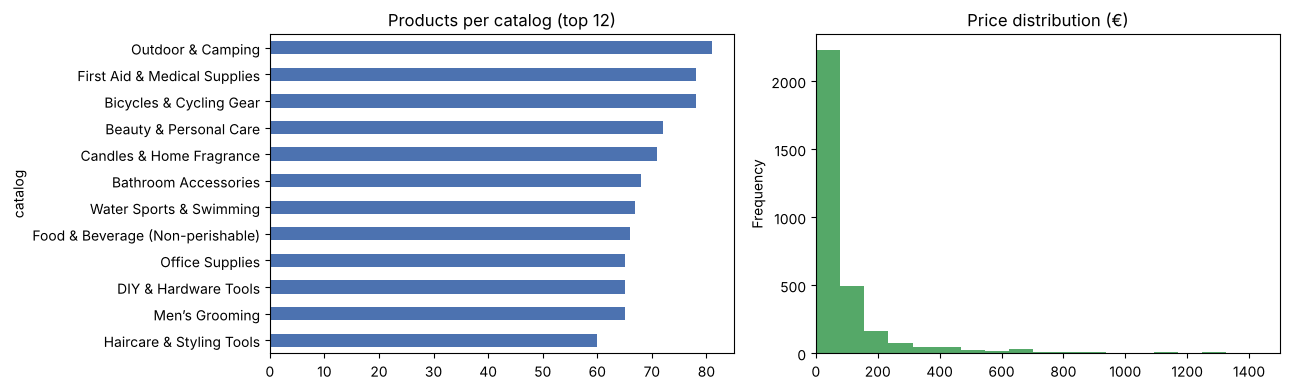

In [13]:
import matplotlib.pyplot as plt

current = products[products.status == "current"].copy()
current["price_eur"] = current.price_eur.astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
current.groupby("catalog").size().sort_values().tail(12).rename(lambda c: c.split("— ")[-1]).plot.barh(
    ax=axes[0], color="#4C72B0", title="Products per catalog (top 12)")
current.price_eur.plot.hist(bins=50, ax=axes[1], logx=False, color="#55A868", title="Price distribution (€)")
axes[1].set_xlim(0, 1500)
plt.tight_layout()

In [14]:
# Availability is free text: normalise it to its first words to see the real categories
current.availability.str.extract(r"^([A-Za-z -]+)")[0].str.strip().str.lower().value_counts().head(10)

0
in stock              2562
limited stock          214
discontinued           171
low stock              166
pre-order               24
backorder               18
seasonal                12
available to order      10
supplier order           9
clearance stock          5
Name: count, dtype: int64

## 1.7 Trap found while exploring: the same SKU for different products

In [15]:
dups = current[current.duplicated("sku", keep=False)].sort_values("sku")
dups[["sku", "name", "price_eur", "catalog", "page"]]

,sku,name,price_eur,catalog,page
414,IS-BED-001,"Nordhaven Percale Bedding Set, White, 140 × 200 cm",49.9,IronStore Product Catalog — Bedding & Linens,1
1651,IS-BED-001,Somnia Cotton Percale Duvet Set,49.9,IronStore Product Catalog — Home Essentials,9
415,IS-BED-002,"LumaCasa Washed Cotton Bedding Set, Sage, 200 × 200 cm",69.9,IronStore Product Catalog — Bedding & Linens,2
1652,IS-BED-002,Restwell Memory Foam Pillow,34.0,IronStore Product Catalog — Home Essentials,10
416,IS-BED-003,"Hestia Home Sateen Bedding Set, Navy, 240 × 220 cm",89.9,IronStore Product Catalog — Bedding & Linens,3
1653,IS-BED-003,WarmNest All-Season Duvet,62.0,IronStore Product Catalog — Home Essentials,11
417,IS-BED-004,"Fjord & Field Linen Blend Bedding Set, Natural, 200 × 200 cm",119.0,IronStore Product Catalog — Bedding & Linens,3
1677,IS-BED-004,SleepArc Electric Heated Throw,64.0,IronStore Product Catalog — Home Essentials,23


This one wasn't mentioned anywhere: `IS-BED-001` is a bedding set in one catalog and a duvet set in another,
`IS-BED-002` a bedding set *and* a pillow. A lookup by SKU must therefore return **both** and warn the user,
never silently pick one (see `lookup_product` in notebook 5).

## 1.8 Everything in one report

In [16]:
for issue, items in result.issues.items():
    print(f"{issue}: {len(items)}")

Policies without a version number: 10
Document ID shared by different documents: 1
Outdated documents (excluded from answers by default): 1
SKU reused by different products: 4
Products with missing price or availability: 2


`python -m ironstore_assistant.ingest` writes the full report to `data/data_quality_report.md`
(a copy is in `docs/`). Next: turning these clean chunks into vectors → **notebook 2**.